<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/mathematical_biology/mathbio_colab_visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Mathematical Biology* — `mathbio_colab_visualizations.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Mathematical Biology — Colab Visualizations
**Ch 1–4 · PSE Lab · SeoulTech · Tong (Cambridge)**

Figures saved to `figures/mathbio/`. Each cell is self-contained.

| Plot | Chapter | Topic |
|------|---------|-------|
| 1 | Ch 1.1 | Logistic growth: solutions, phase portrait, bifurcation |
| 2 | Ch 1.4–1.5 | Lotka-Volterra phase plane + SIR epidemic |
| 3 | Ch 2.2 | Logistic map: bifurcation diagram + Lyapunov exponent |
| 4 | Ch 3.2–3.3 | KPP-Fisher travelling wave + Turing dispersion |
| 5 | Ch 3.3, 1.7 | Turing patterns (1D/2D) + FitzHugh-Nagumo |
| 6 | Ch 2.3 | Feigenbaum universality + self-similarity |
| 7 | Ch 4 | Fokker-Planck spreading + birth-death extinction |

---
## Plot 1 · Logistic Growth (Ch 1.1)

**Left**: $N(t)$ solutions for various $N_0$ — all converge to $K$. **Centre**: Phase portrait $f(N)=\dot N$ — arrows show flow direction. **Right**: Bifurcation diagram in $r$ — transcritical bifurcation at $r=0$.

  saved -> figures/mathbio/plot1_logistic.png


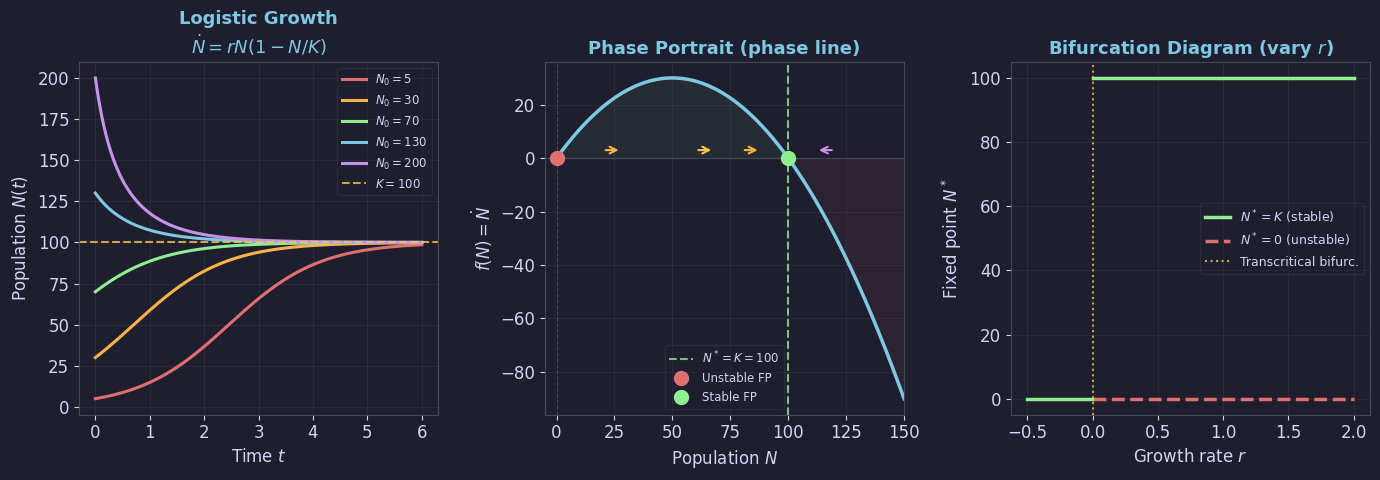

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/mathbio'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── Plot 1: Logistic Growth — solutions, phase portrait, bifurcation (Ch 1.1) ─
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

r, K = 1.2, 100
t = np.linspace(0, 6, 300)

ax = axes[0]
for N0, col in [(5,RED),(30,ORANGE),(70,GREEN),(130,BLUE),(200,PURPLE)]:
    N = K*N0*np.exp(r*t)/(K + N0*(np.exp(r*t)-1))
    ax.plot(t, N, color=col, lw=2.2, label=f'$N_0={N0}$')
ax.axhline(K, color=YELLOW, lw=1.5, ls='--', alpha=0.8, label=f'$K={K}$')
ax.set_xlabel('Time $t$'); ax.set_ylabel('Population $N(t)$')
ax.set_title('Logistic Growth\n'+r'$\dot N=rN(1-N/K)$', color=BLUE)
ax.legend(fontsize=8.5, labelcolor=FG); ax.grid(True)

N_arr = np.linspace(0, 1.5*K, 400)
fN = r*N_arr*(1-N_arr/K)
ax2 = axes[1]
ax2.plot(N_arr, fN, color=BLUE, lw=2.5)
ax2.axhline(0, color=EDGE, lw=0.8); ax2.axvline(0, color=EDGE, lw=0.8, ls='--')
ax2.axvline(K, color=GREEN, lw=1.5, ls='--', alpha=0.8, label=f'$N^*=K={K}$')
ax2.plot([0],[0],'o',color=RED,ms=10,zorder=5,label='Unstable FP')
ax2.plot([K],[0],'o',color=GREEN,ms=10,zorder=5,label='Stable FP')
for N0, col in [(20,ORANGE),(60,YELLOW),(80,ORANGE),(120,PURPLE)]:
    fval=r*N0*(1-N0/K); dx=np.sign(fval)*8
    ax2.annotate('',xy=(N0+dx,3),xytext=(N0,3),
                arrowprops=dict(arrowstyle='->',color=col,lw=1.5,mutation_scale=12))
ax2.fill_between(N_arr[(N_arr>0)&(N_arr<K)],0,fN[(N_arr>0)&(N_arr<K)],
                 color=GREEN,alpha=0.07)
ax2.fill_between(N_arr[N_arr>K],0,fN[N_arr>K],color=RED,alpha=0.07)
ax2.set_xlabel('Population $N$'); ax2.set_ylabel(r'$f(N)=\dot N$')
ax2.set_title('Phase Portrait (phase line)', color=BLUE)
ax2.legend(fontsize=8.5, labelcolor=FG); ax2.grid(True); ax2.set_xlim(-5,1.5*K)

r_arr = np.linspace(-0.5, 2.0, 300)
ax3 = axes[2]
ax3.plot(r_arr[r_arr>0], K*np.ones(sum(r_arr>0)), color=GREEN, lw=2.5,
         label='$N^*=K$ (stable)')
ax3.plot(r_arr[r_arr>0], np.zeros(sum(r_arr>0)), color=RED, lw=2.5, ls='--',
         label='$N^*=0$ (unstable)')
ax3.plot(r_arr[r_arr<=0], np.zeros(sum(r_arr<=0)), color=GREEN, lw=2.5)
ax3.axvline(0, color=YELLOW, lw=1.5, ls=':', alpha=0.8, label='Transcritical bifurc.')
ax3.set_xlabel('Growth rate $r$'); ax3.set_ylabel('Fixed point $N^*$')
ax3.set_title('Bifurcation Diagram (vary $r$)', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)

plt.tight_layout(pad=1.2)
save('plot1_logistic.png', fig)


---
## Plot 2 · Lotka-Volterra & SIR (Ch 1.4–1.5)

**Left**: Phase plane — closed orbits around the interior fixed point $(d/c,\ a/b)$. **Centre**: Predator-prey oscillations $N(t)$, $P(t)$. **Right**: SIR epidemic curves for $R_0=1.5, 2.5, 4.0$.

  saved -> figures/mathbio/plot2_lotka_volterra_sir.png


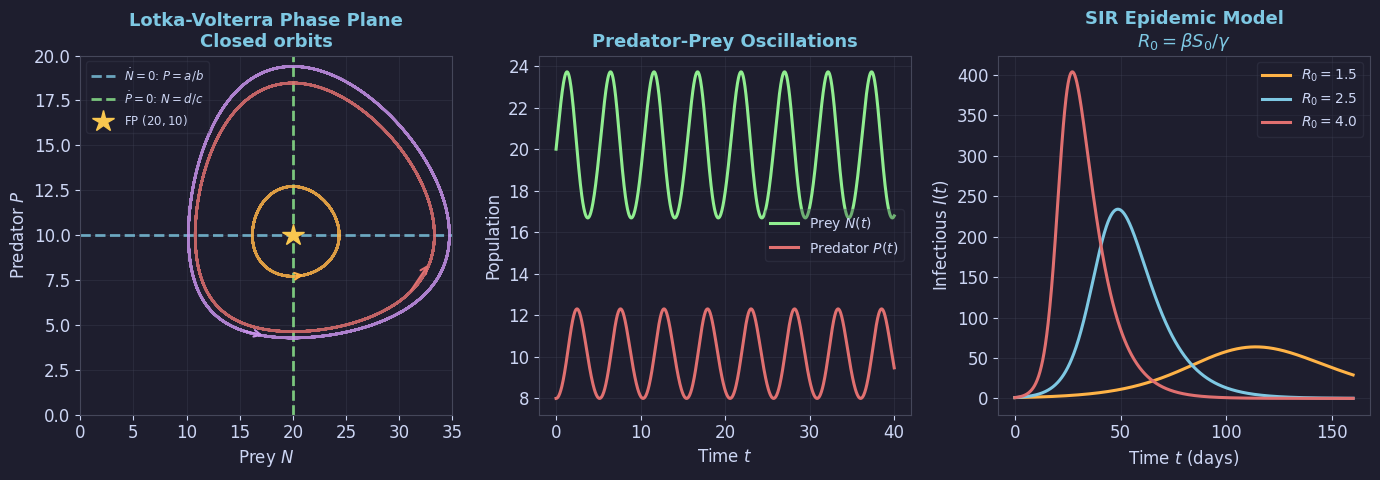

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/mathbio'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── Plot 2: Lotka-Volterra phase plane + SIR epidemic (Ch 1.4–1.5) ─────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

a,b,c,d = 1.0, 0.1, 0.075, 1.5
N_star, P_star = d/c, a/b

def lv(t, y): return [a*y[0]-b*y[0]*y[1], c*y[0]*y[1]-d*y[1]]

ax = axes[0]
ax.axhline(a/b, color=BLUE, lw=2.0, ls='--', label=r'$\dot N=0$: $P=a/b$', alpha=0.8)
ax.axvline(d/c, color=GREEN, lw=2.0, ls='--', label=r'$\dot P=0$: $N=d/c$', alpha=0.8)
ax.plot([N_star],[P_star],'*',color=YELLOW,ms=16,zorder=5,
        label=f'FP $({N_star:.0f},{P_star:.0f})$')
for N0_ic, P0_ic, col in [(25,5,RED),(18,8,ORANGE),(12,6,PURPLE)]:
    sol=solve_ivp(lv,[0,50],[N0_ic,P0_ic],max_step=0.05,dense_output=True)
    l_arr=np.linspace(0,50,2000); traj=sol.sol(l_arr)
    ax.plot(traj[0],traj[1],color=col,lw=1.8,alpha=0.85)
    ax.annotate('',xy=(traj[0][30],traj[1][30]),xytext=(traj[0][20],traj[1][20]),
               arrowprops=dict(arrowstyle='->',color=col,lw=1.5,mutation_scale=12))
ax.set_xlabel('Prey $N$'); ax.set_ylabel('Predator $P$')
ax.set_title('Lotka-Volterra Phase Plane\nClosed orbits', color=BLUE)
ax.legend(fontsize=8.5, labelcolor=FG); ax.grid(True)
ax.set_xlim(0,35); ax.set_ylim(0,20)

ax2 = axes[1]
sol2=solve_ivp(lv,[0,40],[20,8],max_step=0.05,dense_output=True)
t_arr=np.linspace(0,40,1000); traj2=sol2.sol(t_arr)
ax2.plot(t_arr,traj2[0],color=GREEN,lw=2.2,label='Prey $N(t)$')
ax2.plot(t_arr,traj2[1],color=RED,lw=2.2,label='Predator $P(t)$')
ax2.set_xlabel('Time $t$'); ax2.set_ylabel('Population')
ax2.set_title('Predator-Prey Oscillations', color=BLUE)
ax2.legend(fontsize=10, labelcolor=FG); ax2.grid(True)

def sir(t, y, beta=0.3, gamma=0.1, N=1000):
    S,I,R=y
    return [-beta*S*I/N, beta*S*I/N-gamma*I, gamma*I]

ax3 = axes[2]
for R0_val, col, lab in [(1.5,ORANGE,'$R_0=1.5$'),(2.5,BLUE,'$R_0=2.5$'),
                          (4.0,RED,'$R_0=4.0$')]:
    beta=R0_val*0.1
    sol3=solve_ivp(sir,[0,160],[999,1,0],args=(beta,0.1,1000),
                   max_step=0.5,dense_output=True)
    t3=np.linspace(0,160,1000); traj3=sol3.sol(t3)
    ax3.plot(t3,traj3[1],color=col,lw=2.2,label=lab)
ax3.set_xlabel('Time $t$ (days)'); ax3.set_ylabel('Infectious $I(t)$')
ax3.set_title('SIR Epidemic Model\n'+r'$R_0=\beta S_0/\gamma$', color=BLUE)
ax3.legend(fontsize=10, labelcolor=FG); ax3.grid(True)

plt.tight_layout(pad=1.2)
save('plot2_lotka_volterra_sir.png', fig)


---
## Plot 3 · Logistic Map (Ch 2.2)

**Left**: Full bifurcation diagram $x_n$ vs $r$ — period-doubling route to chaos. **Centre**: Zoom into period-doubling cascade. **Right**: Lyapunov exponent — chaos ($\lambda>0$) alternates with periodic windows.

  saved -> figures/mathbio/plot3_logistic_map.png


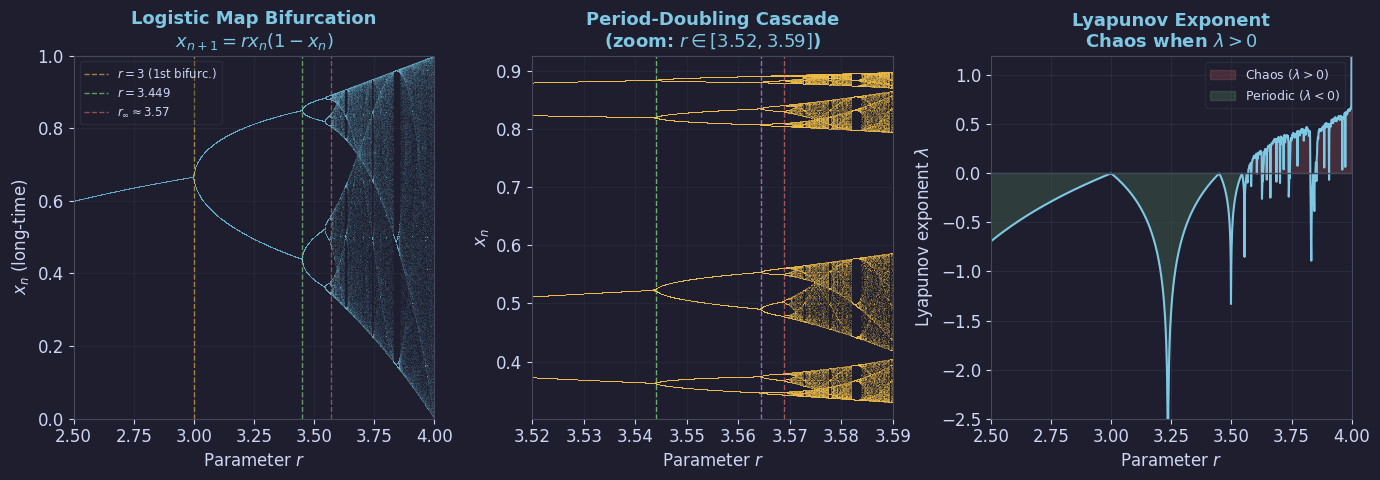

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/mathbio'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── Plot 3: Logistic map — bifurcation, cascade, Lyapunov (Ch 2) ────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

ax = axes[0]
r_vals = np.linspace(2.5, 4.0, 1500)
x = 0.5*np.ones(len(r_vals))
for _ in range(500): x = r_vals*x*(1-x)
xb=[]; rb=[]
for _ in range(200):
    x=r_vals*x*(1-x); xb.extend(x); rb.extend(r_vals)
ax.scatter(rb, xb, s=0.08, c=BLUE, alpha=0.25, linewidths=0)
ax.axvline(3.0, color=YELLOW,lw=1.0,ls='--',alpha=0.6,label='$r=3$ (1st bifurc.)')
ax.axvline(3.449,color=GREEN, lw=1.0,ls='--',alpha=0.6,label='$r=3.449$')
ax.axvline(3.5699,color=RED,  lw=1.0,ls='--',alpha=0.6,label=r'$r_\infty\approx3.57$')
ax.set_xlabel('Parameter $r$'); ax.set_ylabel('$x_n$ (long-time)')
ax.set_title('Logistic Map Bifurcation\n'+r'$x_{n+1}=rx_n(1-x_n)$', color=BLUE)
ax.legend(loc='upper left', fontsize=8.5, labelcolor=FG); ax.grid(True, alpha=0.2)
ax.set_xlim(2.5,4.0); ax.set_ylim(0,1)

ax2 = axes[1]
r_vals2 = np.linspace(3.52,3.59,800)
x2=0.5*np.ones(len(r_vals2)); xb2=[]; rb2=[]
for _ in range(500): x2=r_vals2*x2*(1-x2)
for _ in range(300):
    x2=r_vals2*x2*(1-x2); xb2.extend(x2); rb2.extend(r_vals2)
ax2.scatter(rb2, xb2, s=0.2, c=YELLOW, alpha=0.3, linewidths=0)
for ri, col in zip([3.544,3.5644,3.5688],[GREEN,PURPLE,RED]):
    ax2.axvline(ri, color=col, lw=1.0, ls='--', alpha=0.7)
ax2.set_xlabel('Parameter $r$'); ax2.set_ylabel('$x_n$')
ax2.set_title('Period-Doubling Cascade\n(zoom: $r\\in[3.52,3.59]$)', color=BLUE)
ax2.grid(True, alpha=0.2); ax2.set_xlim(3.52,3.59)

ax3 = axes[2]
r_lya = np.linspace(2.5, 4.0, 1200)
lya = np.zeros_like(r_lya)
for i,ri in enumerate(r_lya):
    xl=0.5; lam=0.0
    for _ in range(500): xl=ri*xl*(1-xl)
    for _ in range(500):
        xl=ri*xl*(1-xl); der=abs(ri*(1-2*xl))
        if der>0: lam+=np.log(der)
    lya[i]=lam/500
ax3.plot(r_lya, lya, color=BLUE, lw=1.5)
ax3.axhline(0, color=EDGE, lw=1.0)
ax3.fill_between(r_lya, lya, 0, where=(lya>0), color=RED, alpha=0.2, label='Chaos ($\\lambda>0$)')
ax3.fill_between(r_lya, lya, 0, where=(lya<0), color=GREEN, alpha=0.15, label='Periodic ($\\lambda<0$)')
ax3.set_xlabel('Parameter $r$'); ax3.set_ylabel('Lyapunov exponent $\\lambda$')
ax3.set_title('Lyapunov Exponent\nChaos when $\\lambda>0$', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)
ax3.set_xlim(2.5,4.0); ax3.set_ylim(-2.5,1.2)

plt.tight_layout(pad=1.2)
save('plot3_logistic_map.png', fig)


---
## Plot 4 · KPP-Fisher Wave & Turing Dispersion (Ch 3.2–3.3)

**Left**: Travelling wave profiles for $c=c_{\min}$ and $c>c_{\min}$. **Centre**: Space-time evolution showing front propagation. **Right**: Turing dispersion relation $\sigma(k^2)$ — unstable band for finite $k$.

  saved -> figures/mathbio/plot4_kpp_turing.png


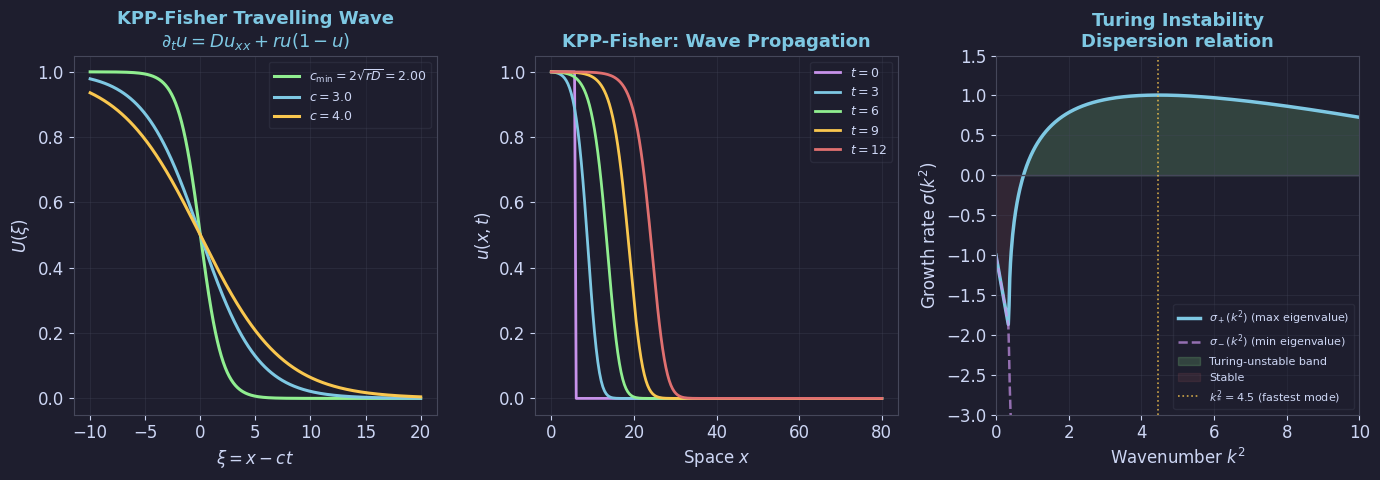

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/mathbio'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── Plot 4: KPP-Fisher wave + Turing dispersion (Ch 3.2–3.3) ───────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

D_kpp, r_kpp = 1.0, 1.0; c_min = 2*np.sqrt(r_kpp*D_kpp)
x = np.linspace(-10, 20, 500)
ax = axes[0]
for c_val, col, lab in [(c_min,GREEN,f'$c_{{\\min}}=2\\sqrt{{rD}}={c_min:.2f}$'),
                         (3.0,BLUE,'$c=3.0$'),(4.0,YELLOW,'$c=4.0$')]:
    lam=(c_val-np.sqrt(max(c_val**2-4*r_kpp*D_kpp,0)))/(2*D_kpp)
    U=1/(1+np.exp(lam*x))
    ax.plot(x, U, color=col, lw=2.2, label=lab)
ax.set_xlabel(r'$\xi=x-ct$'); ax.set_ylabel(r'$U(\xi)$')
ax.set_title('KPP-Fisher Travelling Wave\n'+r'$\partial_t u=Du_{xx}+ru(1-u)$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)

# Finite difference simulation
ax2 = axes[1]
Nx=200; dx=0.4; dt=0.01; D=1.0; r=1.0
x2=np.linspace(0,Nx*dx,Nx); u=np.zeros(Nx); u[:15]=1.0
nu_kpp=D*dt/dx**2; times_plot=[0,3,6,9,12]; cols2=[PURPLE,BLUE,GREEN,YELLOW,RED]
u_snap=[u.copy()]; t_now=0; si=1
while t_now < 12+dt:
    lap=np.roll(u,-1)-2*u+np.roll(u,1); lap[0]=lap[-1]=0
    u=u+dt*(D*lap/dx**2+r*u*(1-u)); u=np.clip(u,0,1); t_now+=dt
    if si<len(times_plot) and t_now>=times_plot[si]-dt/2:
        u_snap.append(u.copy()); si+=1
for i,(snap,col) in enumerate(zip(u_snap,cols2)):
    ax2.plot(x2,snap,color=col,lw=2.0,label=f'$t={times_plot[i]}$')
ax2.set_xlabel('Space $x$'); ax2.set_ylabel('$u(x,t)$')
ax2.set_title('KPP-Fisher: Wave Propagation', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)

# Turing dispersion relation — activator-inhibitor (Du=0.1, Dv=5)
ax3 = axes[2]
k2=np.linspace(0,10,500)
fu,fv,gu,gv=2.0,-5.0,3.0,-4.0; Du_t,Dv_t=0.1,5.0
h_k=(fu+gv)-(Du_t+Dv_t)*k2
det_k=(fu-Du_t*k2)*(gv-Dv_t*k2)-fv*gu
disc=h_k**2-4*det_k
sigma_p=np.where(disc>=0,(h_k+np.sqrt(np.maximum(disc,0)))/2,h_k/2)
sigma_m=np.where(disc>=0,(h_k-np.sqrt(np.maximum(disc,0)))/2,h_k/2)
k_star2=k2[sigma_p.argmax()]
ax3.plot(k2, sigma_p, color=BLUE, lw=2.5, label=r'$\sigma_+(k^2)$ (max eigenvalue)')
ax3.plot(k2, sigma_m, color=PURPLE, lw=1.8, ls='--',
         label=r'$\sigma_-(k^2)$ (min eigenvalue)', alpha=0.7)
ax3.axhline(0, color=EDGE, lw=1.0)
ax3.fill_between(k2, sigma_p, 0, where=(sigma_p>0),
                 color=GREEN, alpha=0.18, label='Turing-unstable band')
ax3.fill_between(k2, sigma_p, 0, where=(sigma_p<0),
                 color=RED, alpha=0.10, label='Stable')
ax3.axvline(k_star2, color=YELLOW, lw=1.2, ls=':', alpha=0.8,
            label=f'$k^2_*={k_star2:.1f}$ (fastest mode)')
ax3.set_xlabel('Wavenumber $k^2$')
ax3.set_ylabel(r'Growth rate $\sigma(k^2)$')
ax3.set_title('Turing Instability\nDispersion relation', color=BLUE)
ax3.legend(fontsize=8, labelcolor=FG, loc='lower right')
ax3.grid(True); ax3.set_xlim(0,10); ax3.set_ylim(-3,1.5)

plt.tight_layout(pad=1.2)
save('plot4_kpp_turing.png', fig)

---
## Plot 5 · Turing Patterns & FitzHugh-Nagumo (Ch 3.3, 1.7)

**Left**: 1D Turing pattern (Schnakenberg model) — activator peaks where inhibitor dips. **Centre**: 2D Gray-Scott spot pattern. **Right**: FitzHugh-Nagumo phase plane — limit cycle (excitability).

  saved -> figures/mathbio/plot5_turing_fhn.png


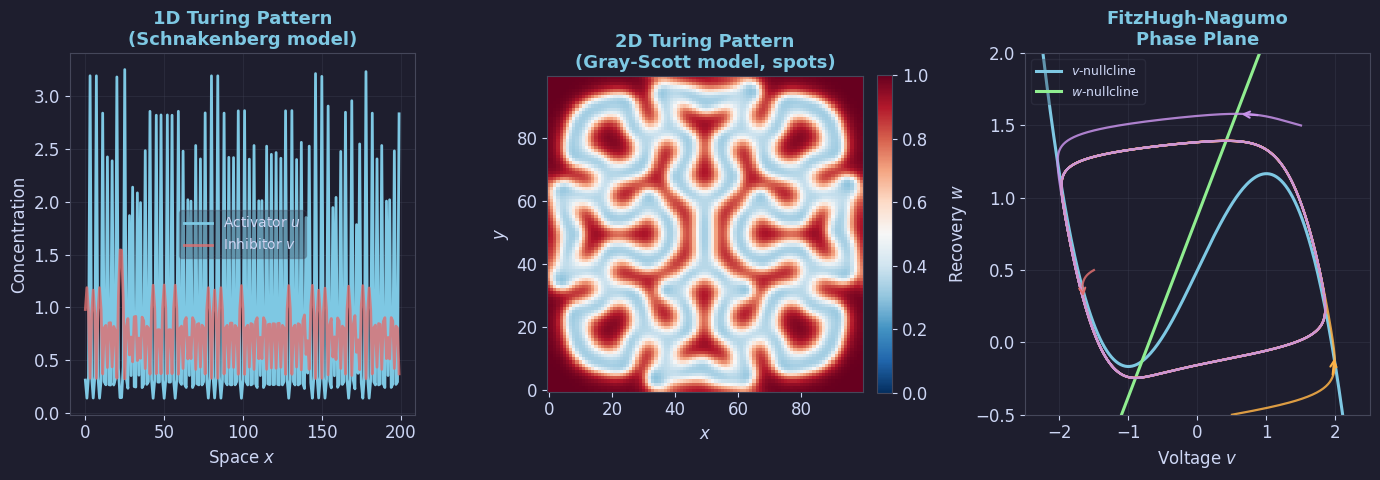

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/mathbio'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── Plot 5: Turing patterns + FitzHugh-Nagumo (Ch 3.3, 1.7) ────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# 1D Schnakenberg Turing pattern
def run_schnakenberg(Nx=200, steps=80000, dt=0.05, Du=0.05, Dv=2.0, a=0.1, b=0.9):
    np.random.seed(42)
    ss_u=a+b; ss_v=b/(a+b)**2
    u=ss_u+0.02*(np.random.rand(Nx)-0.5)
    v=ss_v+0.02*(np.random.rand(Nx)-0.5)
    ku=Du*dt; kv=Dv*dt
    for _ in range(steps):
        lap_u=np.roll(u,-1)-2*u+np.roll(u,1)
        lap_v=np.roll(v,-1)-2*v+np.roll(v,1)
        u=u+dt*(a-u+u**2*v)+ku*lap_u
        v=v+dt*(b-u**2*v)+kv*lap_v
        u=np.clip(u,1e-6,10); v=np.clip(v,1e-6,10)
    return u, v

u1d,v1d=run_schnakenberg()
ax=axes[0]
ax.plot(np.arange(len(u1d)), u1d, color=BLUE, lw=2.0, label='Activator $u$')
ax.plot(np.arange(len(u1d)), v1d, color=RED, lw=2.0, label='Inhibitor $v$', alpha=0.8)
ax.set_xlabel('Space $x$'); ax.set_ylabel('Concentration')
ax.set_title('1D Turing Pattern\n(Schnakenberg model)', color=BLUE)
ax.legend(fontsize=10, labelcolor=FG); ax.grid(True)

# 2D Gray-Scott spots
def run_gray_scott(N=100, steps=5000, dt=1.0, Du=0.16, Dv=0.08, F=0.060, k=0.062):
    np.random.seed(5)
    u=np.ones((N,N)); v=np.zeros((N,N))
    s=10; mid=N//2
    u[mid-s:mid+s,mid-s:mid+s]=0.50; v[mid-s:mid+s,mid-s:mid+s]=0.25
    u+=0.01*np.random.randn(N,N); v+=0.01*np.random.randn(N,N)
    u=np.clip(u,0,1); v=np.clip(v,0,1)
    for _ in range(steps):
        Lu=(np.roll(u,-1,0)+np.roll(u,1,0)+np.roll(u,-1,1)+np.roll(u,1,1)-4*u)
        Lv=(np.roll(v,-1,0)+np.roll(v,1,0)+np.roll(v,-1,1)+np.roll(v,1,1)-4*v)
        uvv=u*v*v
        u+=dt*(Du*Lu-uvv+F*(1-u)); v+=dt*(Dv*Lv+uvv-(F+k)*v)
        u=np.clip(u,0,1); v=np.clip(v,0,1)
    return u

u2d=run_gray_scott()
ax2=axes[1]
im=ax2.imshow(u2d, cmap='RdBu_r', origin='lower', vmin=0.0, vmax=1.0)
plt.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)
ax2.set_title('2D Turing Pattern\n(Gray-Scott model, spots)', color=BLUE)
ax2.set_xlabel('$x$'); ax2.set_ylabel('$y$')

# FitzHugh-Nagumo phase plane
def fhn(t, y, I_ext=0.5, a=0.7, b=0.8, tau=12.5):
    v,w=y
    return [v-v**3/3-w+I_ext, (v+a-b*w)/tau]

v_arr=np.linspace(-2.5,2.5,300)
ax3=axes[2]
ax3.plot(v_arr, v_arr-v_arr**3/3+0.5, color=BLUE, lw=2.2, label='$v$-nullcline')
ax3.plot(v_arr, (v_arr+0.7)/0.8, color=GREEN, lw=2.2, label='$w$-nullcline')
for v0,w0,col in [(-1.5,0.5,RED),(0.5,-0.5,ORANGE),(1.5,1.5,PURPLE)]:
    sol_f=solve_ivp(fhn,[0,100],[v0,w0],max_step=0.05,dense_output=True)
    tr=sol_f.sol(np.linspace(0,100,3000))
    ax3.plot(tr[0],tr[1],color=col,lw=1.6,alpha=0.85)
    ax3.annotate('',xy=(tr[0][60],tr[1][60]),xytext=(tr[0][40],tr[1][40]),
               arrowprops=dict(arrowstyle='->',color=col,lw=1.5,mutation_scale=11))
ax3.set_xlabel('Voltage $v$'); ax3.set_ylabel('Recovery $w$')
ax3.set_title('FitzHugh-Nagumo\nPhase Plane', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)
ax3.set_xlim(-2.5,2.5); ax3.set_ylim(-0.5,2.0)

plt.tight_layout(pad=1.2)
save('plot5_turing_fhn.png', fig)


---
## Plot 6 · Feigenbaum Universality (Ch 2.3)

**Left**: Convergence of period-doubling ratios to $\delta\approx4.669$. **Centre**: Period-3 window — self-similar structure. **Right**: Universality — logistic and sine maps have identical bifurcation structure.

  saved -> figures/mathbio/plot6_feigenbaum.png


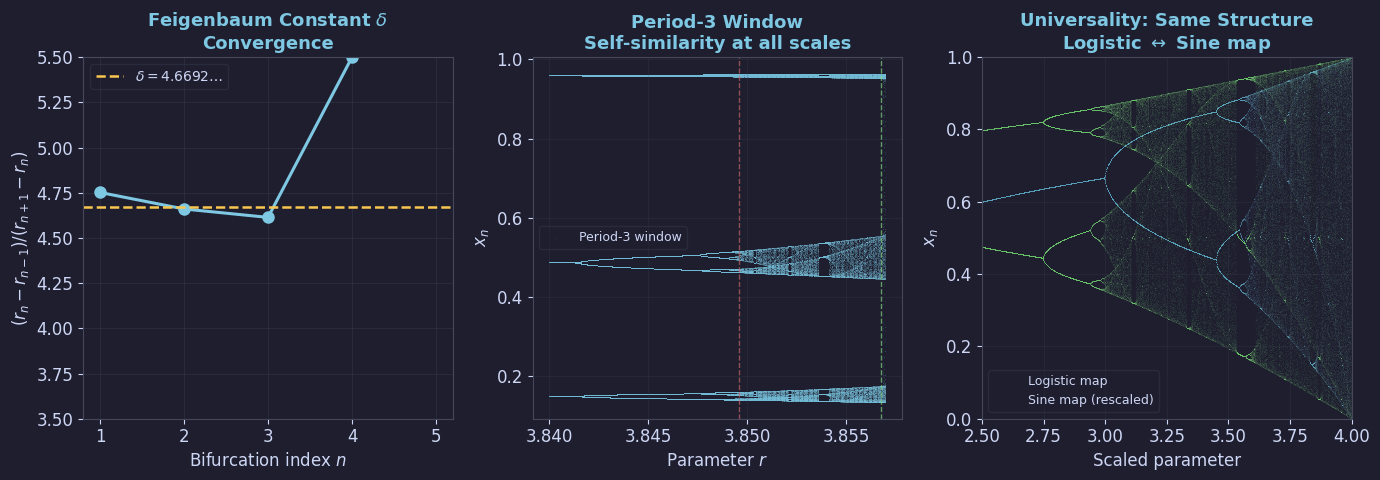

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/mathbio'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── Plot 6: Feigenbaum universality (Ch 2.3) ────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

r_n = [3.0, 3.4495, 3.5441, 3.5644, 3.5688, 3.5696, 3.56969]
deltas = [(r_n[i]-r_n[i-1])/(r_n[i+1]-r_n[i]) for i in range(1,len(r_n)-1)]
ax=axes[0]
ax.plot(range(1,len(deltas)+1), deltas, color=BLUE, lw=2.2, marker='o', ms=8)
ax.axhline(4.6692, color=YELLOW, lw=1.8, ls='--', label=r'$\delta=4.6692\ldots$')
ax.set_xlabel('Bifurcation index $n$')
ax.set_ylabel(r'$(r_n-r_{n-1})/(r_{n+1}-r_n)$')
ax.set_title('Feigenbaum Constant $\\delta$\nConvergence', color=BLUE)
ax.legend(fontsize=10, labelcolor=FG); ax.grid(True); ax.set_ylim(3.5,5.5)

ax2=axes[1]
r_full=np.linspace(3.84,3.857,600)
xf=0.5*np.ones(len(r_full)); xb=[]; rb=[]
for _ in range(500): xf=r_full*xf*(1-xf)
for _ in range(256): xf=r_full*xf*(1-xf); xb.extend(xf); rb.extend(r_full)
ax2.scatter(rb, xb, s=0.15, c=BLUE, alpha=0.3, linewidths=0, label='Period-3 window')
ax2.axvline(3.8496, color=RED, lw=1.0, ls='--', alpha=0.6)
ax2.axvline(3.8568, color=GREEN, lw=1.0, ls='--', alpha=0.6)
ax2.set_xlabel('Parameter $r$'); ax2.set_ylabel('$x_n$')
ax2.set_title('Period-3 Window\nSelf-similarity at all scales', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True, alpha=0.2)

ax3=axes[2]
r_log=np.linspace(2.5,4.0,800)
xl=0.5*np.ones(len(r_log)); xbl=[]; rbl=[]
for _ in range(500): xl=r_log*xl*(1-xl)
for _ in range(150): xl=r_log*xl*(1-xl); xbl.extend(xl); rbl.extend(r_log)
ax3.scatter(np.array(rbl), np.array(xbl), s=0.08, c=BLUE, alpha=0.2,
            linewidths=0, label='Logistic map')
r_sin=np.linspace(0.8,1.0,800)
xs=0.5*np.ones(len(r_sin)); xbs=[]; rbs=[]
for _ in range(500): xs=r_sin*np.sin(np.pi*xs)
for _ in range(150): xs=r_sin*np.sin(np.pi*xs); xbs.extend(xs); rbs.extend(r_sin)
r_sin_sc=(np.array(rbs)-0.8)/0.2*1.5+2.5
ax3.scatter(r_sin_sc, np.array(xbs), s=0.08, c=GREEN, alpha=0.2,
            linewidths=0, label='Sine map (rescaled)')
ax3.set_xlabel('Scaled parameter'); ax3.set_ylabel('$x_n$')
ax3.set_title('Universality: Same Structure\nLogistic $\\leftrightarrow$ Sine map', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True, alpha=0.2)
ax3.set_xlim(2.5,4.0); ax3.set_ylim(0,1)

plt.tight_layout(pad=1.2)
save('plot6_feigenbaum.png', fig)


---
## Plot 7 · Fokker-Planck & Birth-Death (Ch 4)

**Left**: Fokker-Planck spreading Gaussians with drift. **Centre**: Extinction probability $p_{\rm ext}=\delta/\beta$ vs birth rate. **Right**: Birth-death master equation — distribution $p_n(t)$ evolves from $n_0=5$.

  saved -> figures/mathbio/plot7_fokker_planck.png


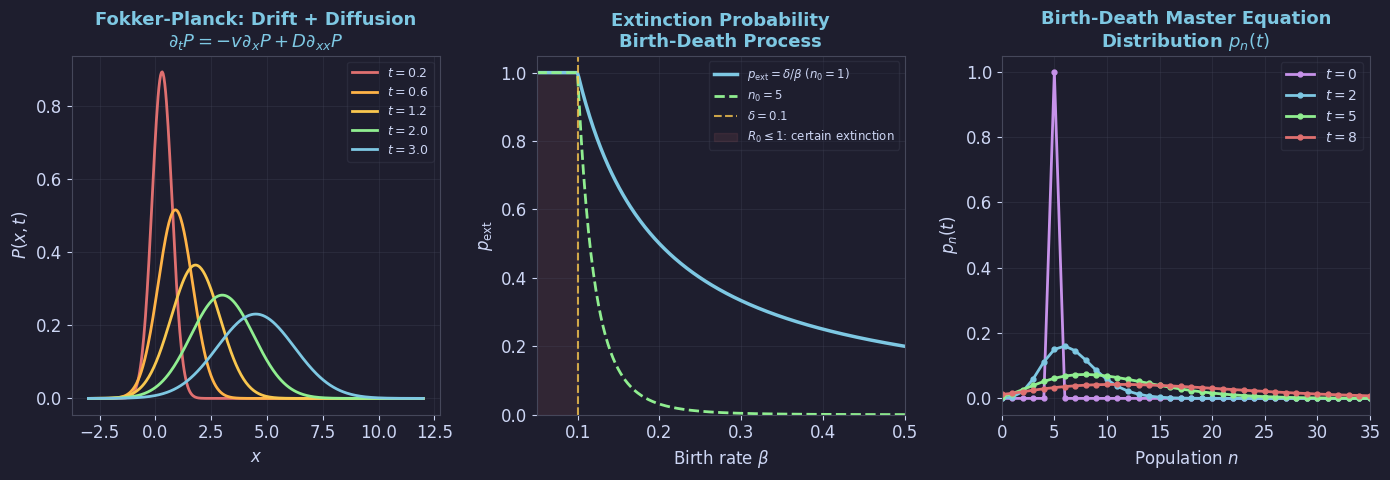

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/mathbio'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── Plot 7: Fokker-Planck / Birth-Death Process (Ch 4) ──────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

x_fp=np.linspace(-3,12,400); v_drift=1.5; D_fp=0.5
ax=axes[0]
for t_val,col,lab in [(0.2,RED,'$t=0.2$'),(0.6,ORANGE,'$t=0.6$'),
                       (1.2,YELLOW,'$t=1.2$'),(2.0,GREEN,'$t=2.0$'),(3.0,BLUE,'$t=3.0$')]:
    mean=v_drift*t_val; var=2*D_fp*t_val
    P=np.exp(-(x_fp-mean)**2/(2*var))/np.sqrt(2*np.pi*var)
    ax.plot(x_fp, P, color=col, lw=2.0, label=lab)
ax.set_xlabel('$x$'); ax.set_ylabel('$P(x,t)$')
ax.set_title('Fokker-Planck: Drift + Diffusion\n'+
             r'$\partial_t P=-v\partial_xP+D\partial_{xx}P$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)

beta_arr=np.linspace(0.05,0.5,300); delta=0.1
p_ext=np.where(beta_arr>delta, delta/beta_arr, 1.0)
ax2=axes[1]
ax2.plot(beta_arr, p_ext, color=BLUE, lw=2.5,
         label=r'$p_{\rm ext}=\delta/\beta$ ($n_0=1$)')
ax2.plot(beta_arr, p_ext**5, color=GREEN, lw=2.0, ls='--', label=r'$n_0=5$')
ax2.axvline(delta, color=YELLOW, lw=1.5, ls='--', alpha=0.8, label=f'$\\delta={delta}$')
ax2.fill_between(beta_arr[beta_arr<=delta], 0, 1,
                 color=RED, alpha=0.1, label='$R_0\\leq1$: certain extinction')
ax2.set_xlabel(r'Birth rate $\beta$'); ax2.set_ylabel(r'$p_{\rm ext}$')
ax2.set_title('Extinction Probability\nBirth-Death Process', color=BLUE)
ax2.legend(fontsize=8.5, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(0.05,0.5); ax2.set_ylim(0,1.05)

# Master equation numerical solution
N_max=40; beta_m=0.3; delta_m=0.15
p=np.zeros(N_max+1); p[5]=1.0
dt_m=0.05; T_m=8.0
p_snaps={0:p.copy()}; t_m=0
while t_m<T_m:
    dp=np.zeros_like(p)
    for n in range(N_max+1):
        dp[n]=(beta_m*(n-1)*p[n-1] if n>0 else 0)
        dp[n]+=(delta_m*(n+1)*p[n+1] if n<N_max else 0)
        dp[n]-=(beta_m+delta_m)*n*p[n]
    p=np.maximum(p+dt_m*dp,0)
    s=p.sum(); p=p/s if s>0 else p
    t_m+=dt_m
    for tgt in [2,5,8]:
        if abs(t_m-tgt)<dt_m*0.6 and tgt not in p_snaps:
            p_snaps[tgt]=p.copy()

ax3=axes[2]
n_arr=np.arange(N_max+1)
for t_t,col,lab in [(0,PURPLE,'$t=0$'),(2,BLUE,'$t=2$'),
                     (5,GREEN,'$t=5$'),(8,RED,'$t=8$')]:
    snap=p_snaps.get(t_t, np.zeros(N_max+1))
    ax3.plot(n_arr, snap, color=col, lw=2.0, marker='o', ms=3.5, label=lab)
ax3.set_xlabel('Population $n$'); ax3.set_ylabel('$p_n(t)$')
ax3.set_title('Birth-Death Master Equation\nDistribution $p_n(t)$', color=BLUE)
ax3.legend(fontsize=10, labelcolor=FG); ax3.grid(True); ax3.set_xlim(0,35)

plt.tight_layout(pad=1.2)
save('plot7_fokker_planck.png', fig)


---
## Download All Figures

In [8]:
import os, zipfile
from google.colab import files

OUTDIR = 'figures/mathbio'
saved = sorted([f for f in os.listdir(OUTDIR) if f.endswith('.png')]) \
        if os.path.exists(OUTDIR) else []
print(f'Found {len(saved)} figures:')
for f in saved:
    print(f'  {f}  ({os.path.getsize(f"{OUTDIR}/{f}")//1024} KB)')

zip_name = 'mathbio_colab_visualizations.zip'
with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in saved:
        zf.write(f'{OUTDIR}/{fname}', arcname=fname)
print(f'Zip: {zip_name}  ({os.path.getsize(zip_name)//1024} KB)')
files.download(zip_name)


Found 7 figures:
  plot1_logistic.png  (184 KB)
  plot2_lotka_volterra_sir.png  (251 KB)
  plot3_logistic_map.png  (377 KB)
  plot4_kpp_turing.png  (212 KB)
  plot5_turing_fhn.png  (324 KB)
  plot6_feigenbaum.png  (361 KB)
  plot7_fokker_planck.png  (210 KB)
Zip: mathbio_colab_visualizations.zip  (1844 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>